# IPCA – Decomposição por Subitens

Este notebook apresenta:

**1. O que é decomposição do IPCA**  
**2. Como o IPCA é construído a partir dos subitens**  
**3. Consulta ao banco de dados (subitens + pesos)**  
**4. Cálculo das contribuições**  
**5. Reconstrução do IPCA geral**  
**6. Gráficos profissionais (estilo Banco Central)**  
**7. Decomposição por grupos**

Vamos começar entendendo o conceito.

# 1. O que é a decomposição do IPCA?

O IPCA é um índice **ponderado**.

Cada subitem (ex: arroz, gasolina, aluguel, tomate) tem:

- **índice cheio** → variação mensal daquele subitem  
- **peso** → participação daquele subitem no IPCA  

| Descrição | Desenvolvimento |
|-|-|
| A contribuição de cada subitem é: | $$ contribuição = índice\_cheio \times \frac{peso}{100} $$ |
| A soma de todas as contribuições forma o IPCA geral: | $$ IPCA = \sum contribuições\_{subitens} $$ |



Portanto:

👉 **A decomposição do IPCA é feita pelos subitens.**

# 2. Ajustar o PYTHONPATH

In [1]:
import sys, os
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.append(ROOT)
print("PYTHONPATH atualizado:", ROOT)

PYTHONPATH atualizado: /home/moacir/projects/ml/analytics/inflation


# 3. Importações

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.database.connection import engine

pd.set_option("display.float_format", "{:.6f}".format)

# 4. Carregar dados dos subitens (índice cheio + peso)

In [4]:
query_subitens = """
select
    si.date::date,
    si.category AS "idSubItens",
    si.category_name AS "subItens",
    si.indice AS "indiceCheio",
    si.peso AS "peso",
    (si.indice * (si.peso / 100)) AS "contribuicaoIpca"
from bcb.ipca_subitens si
order by si.date desc, si.category;
"""

df_sub = pd.read_sql(query_subitens, engine)
df_sub.head()

,date,idSubItens,subItens,indiceCheio,peso,contribuicaoIpca
0,2026-03-01,1101002,Arroz,-0.300000,0.498800,-0.001496
1,2026-03-01,1101051,Feijão - mulatinho,4.420000,0.012300,0.000544
2,2026-03-01,1101052,Feijão - preto,7.120000,0.035900,0.002556
3,2026-03-01,1101053,Feijão - macáçar (fradinho),2.290000,0.016000,0.000366
4,2026-03-01,1101073,Feijão - carioca (rajado),15.400000,0.109400,0.016848


# 5. Carregar IPCA geral para comparação

In [6]:
query_ipca = """
Select 
    date::date, 
    indice as ipca
from bcb.ipca
order by date desc;
"""

df_ipca = pd.read_sql(query_ipca, engine)
df_ipca.head()

,date,ipca
0,2026-03-01,0.880000
1,2026-02-01,0.700000
2,2026-01-01,0.330000
3,2025-12-01,0.330000
4,2025-11-01,0.180000


# 6. Soma das contribuições dos subitens (reconstrução do IPCA)

In [10]:
df_sum = (
    df_sub.groupby("date")["contribuicaoIpca"]
    .sum()
    .reset_index()
    .rename(columns={"contribuicaoIpca": "ipca_reconstruido"})
)

df_sum.tail()

,date,ipca_reconstruido
70,2025-11-01,0.175875
71,2025-12-01,0.329183
72,2026-01-01,0.325875
73,2026-02-01,0.700647
74,2026-03-01,0.875233


# 7. Comparar IPCA oficial vs reconstruído

In [18]:
df_compare = df_ipca.merge(df_sum, on="date", how="inner")
df_compare.head(12)

,date,ipca,ipca_reconstruido
0,2026-03-01,0.880000,0.875233
1,2026-02-01,0.700000,0.700647
2,2026-01-01,0.330000,0.325875
3,2025-12-01,0.330000,0.329183
4,2025-11-01,0.180000,0.175875
5,2025-10-01,0.090000,0.087054
6,2025-09-01,0.480000,0.481951
7,2025-08-01,-0.110000,-0.108161
8,2025-07-01,0.260000,0.264052
9,2025-06-01,0.240000,0.237859


# 8. Erro de reconstrução (deve ser muito pequeno)

In [19]:
df_compare["erro"] = df_compare["ipca"] - df_compare["ipca_reconstruido"]
df_compare.describe()

,ipca,ipca_reconstruido,erro
count,75.000000,75.000000,75.000000
mean,0.467867,0.467365,0.000502
std,0.420496,0.419832,0.003049
min,-0.680000,-0.680930,-0.004821
25%,0.240000,0.240192,-0.001968
50%,0.430000,0.434113,0.000930
75%,0.720000,0.718669,0.003056
max,1.620000,1.618636,0.005173


# 9. Gráfico – IPCA oficial vs reconstruído

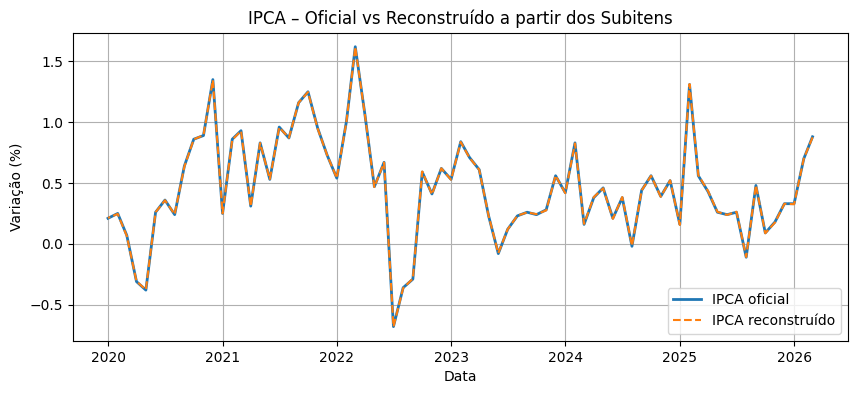

In [25]:
plt.figure(figsize=(10, 4))
plt.plot(df_compare["date"], df_compare["ipca"], label="IPCA oficial", linewidth=2)
plt.plot(df_compare["date"], df_compare["ipca_reconstruido"], label="IPCA reconstruído", linestyle="--")

plt.title("IPCA – Oficial vs Reconstruído a partir dos Subitens")
plt.xlabel("Data")
plt.ylabel("Variação (%)")
plt.grid(True)
plt.legend()
plt.show()

# 10. Decomposição por grupos (via view `vw_groupsBySubItems`)

- A view já contém a hierarquia completa:

    - grupo  
    - subgrupo  
    - item  
    - subitem  

Vamos carregar e agregar.

In [48]:
query_view = """
Select
    g.date::date,
    g."idGrupos",
    g.grupos,
    g."idSubItens",
    g."subItens",
    si.indice AS "indiceCheio",
    si.peso,
    (si.indice * (si.peso / 100)) AS contribuicao
from bcb.ipca_subitens si
left join bcb."vw_groupsBySubItems" g on g."idSubItens" = si.category and g.date = si.date
order by g.date desc;
"""

df_hier = pd.read_sql(query_view, engine)
df_hier["date"] = pd.to_datetime(df_hier["date"])
df_hier.head()

,date,idGrupos,grupos,idSubItens,subItens,indiceCheio,peso,contribuicao
0,2026-03-01,9,Comunicação,9101018,Acesso à internet,0.000000,0.386500,0.000000
1,2026-03-01,9,Comunicação,9101010,Tv por assinatura,0.000000,0.383100,0.000000
2,2026-03-01,9,Comunicação,9101008,Plano de telefonia móvel,1.330000,1.269600,0.016886
3,2026-03-01,9,Comunicação,9101002,Plano de telefonia fixa,0.000000,0.209500,0.000000
4,2026-03-01,9,Comunicação,9101001,Correio,0.000000,0.065400,0.000000


# 11. Contribuição por grupo (último mês)

In [ ]:
ultimo_mes = df_hier["date"].max()

df_grupo = (
    df_hier[df_hier["date"] == ultimo_mes]
    .groupby(["idGrupos", "grupos"])["contribuicao"].sum().reset_index().sort_values("contribuicao", ascending=False)
)

df_grupo

,idGrupos,grupos,contribuicao
4,5,Transportes,0.335956
0,1,Alimentação e bebidas,0.333288
6,7,Despesas pessoais,0.066579
5,6,Saúde e cuidados pessoais,0.056706
1,2,Habitação,0.033870
3,4,Vestuário,0.021262
2,3,Artigos de residência,0.017700
8,9,Comunicação,0.008520
7,8,Educação,0.001352


# 12. Gráfico – Contribuição por grupo (último mês)

/tmp/ipykernel_10156/931093873.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


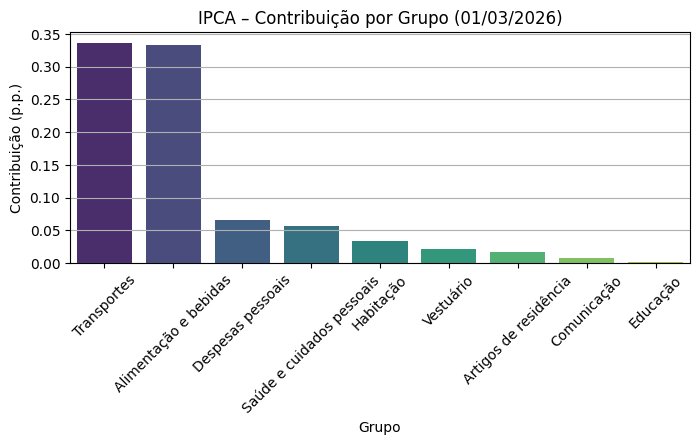

In [57]:
plt.figure(figsize=(8, 3))
sns.barplot(
    data=df_grupo,
    x="grupos",
    y="contribuicao",
    palette="viridis"
)

plt.title(f"IPCA – Contribuição por Grupo ({ultimo_mes.strftime("%d/%m/%Y")})")
plt.xlabel("Grupo")
plt.ylabel("Contribuição (p.p.)")
plt.xticks(rotation=45)
plt.grid(True, axis="y")
plt.show()

# 13. Gráfico – Decomposição acumulada (últimos 12 meses)

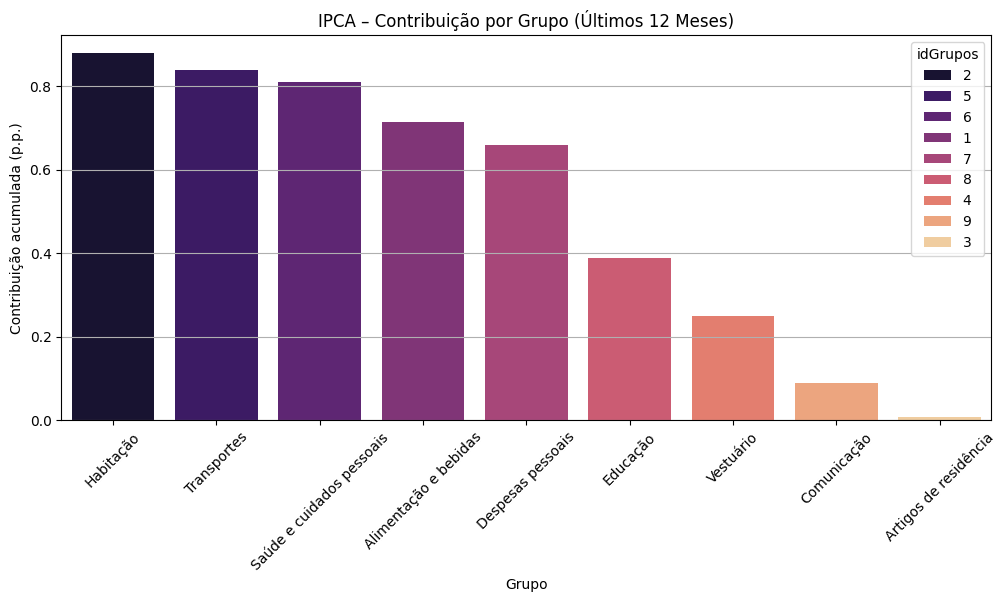

In [47]:
df_12m = (
    df_hier[df_hier["date"] >= (ultimo_mes - pd.DateOffset(months=12))]
    .groupby(["idGrupos", "grupos"])["contribuicao"]
    .sum()
    .reset_index()
    .sort_values("contribuicao", ascending=False)
)

plt.figure(figsize=(12, 5))
sns.barplot(data=df_12m, x="grupos", y="contribuicao", hue="idGrupos", palette="magma")

plt.title("IPCA – Contribuição por Grupo (Últimos 12 Meses)")
plt.xlabel("Grupo")
plt.ylabel("Contribuição acumulada (p.p.)")
plt.xticks(rotation=45)
plt.grid(True, axis="y")
plt.show()

# 14. Conclusões

- A decomposição do IPCA é feita pelos **subitens**, que são o nível mais granular.  
- O IPCA geral pode ser **reconstruído perfeitamente** pela soma das contribuições.  
- A view `vw_groupsBySubItems` permite análises hierárquicas completas.  
- A contribuição por grupo mostra quais setores puxaram a inflação.  
- A estrutura atual do banco permite análises profissionais como as do Banco Central.

Próximos passos:
- decomposição por subgrupos e itens  
- núcleos de inflação (médias aparadas, exclusões)  
- difusão (percentual de subitens com alta)  
- relação IPCA × SELIC  